# Étape 13 bis : améliorer la prédiction à 15 min

**Référence à battre** (étape 13) : régression logistique sur les 11 variables,
log loss **0,524** sur le test (AUC 0,813, 74,1 % de bons pronostics).

La revue de l'étape 13 a conclu que le modèle n'est pas le frein : il faut des
**informations que l'or ne contient pas**, et savoir si **plus de parties** aiderait.
Ce notebook répond à ces deux questions, avec les mêmes règles qu'à l'étape 13
(validation croisée chronologique, test regardé une seule fois à la fin).

Plan :
1. Connexion, données et nouvelles variables
2. Courbe d'apprentissage : plus de parties aiderait-il ?
3. Les nouvelles variables, une par une
4. Réglage de la régularisation
5. LightGBM avec toutes les variables
6. Le test final (une seule fois)
7. Conclusions

## 1. Connexion, données et nouvelles variables

Avant de lancer : Docker Desktop ouvert et `docker compose start` fait.

`build_extra_features()` (nouveau, dans `features.py`) ajoute des **variables candidates**,
calculées par des requêtes séparées pour que le jeu de l'étape 12 reste identique :

| Groupe | Variables | Idée |
|---|---|---|
| or à 10 min | `gold10_k`, `gold_trend_k` | revenir de −2 000 à −500 n'est pas pareil qu'être stable à −500 |
| niveaux | `level_diff` | somme des niveaux bleu − rouge |
| joueur le plus riche | `top_gold_k` | un carry très en avance compte peut-être plus qu'une avance répartie |
| joueurs en vie à 15:00 | `alive_diff` | joueurs tués dans les 30 dernières secondes (encore morts) |
| dragons par type | `drag_<type>_diff` | tous les dragons ne se valent pas |

Toutes utilisent uniquement ce qui s'est passé **avant** la minute 15 : pas de fuite.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from features import (FEATURES, ROLE_FEATURES, TARGET, build_extra_features,
                      build_features, time_split)
from models import (cross_validate, evaluate, fit_predict, make_lgbm, make_logit,
                    paired_bootstrap, time_folds)

warnings.filterwarnings("ignore", message="X does not have valid feature names")
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

df, GROUPS = build_extra_features(build_features())
NEW = [c for cols in GROUPS.values() for c in cols]
train, test = time_split(df, test_frac=0.2)
print(f"{len(df)} parties : {len(train)} entraînement, {len(test)} test (le même découpage qu'à l'étape 13).")
print(f"Valeurs manquantes dans les nouvelles variables : {int(df[NEW].isna().sum().sum())}")

4762 parties : 3809 entraînement, 953 test (le même découpage qu'à l'étape 13).
Valeurs manquantes dans les nouvelles variables : 0


In [2]:
overview = pd.DataFrame({
    "moyenne": df[NEW].mean(), "écart type": df[NEW].std(),
    "min": df[NEW].min(), "max": df[NEW].max(),
    "corrélation victoire": df[NEW].corrwith(df[TARGET]),
    "corrélation avec l'or": df[NEW].corrwith(df["gold_k"]),
})
overview.round(2)

,moyenne,écart type,min,max,corrélation victoire,corrélation avec l'or
gold10_k,0.08,2.09,-8.07,7.38,0.41,0.83
gold_trend_k,-0.04,2.55,-9.80,10.11,0.47,0.89
level_diff,0.01,3.10,-12.00,11.00,0.48,0.89
top_gold_k,0.02,1.31,-5.40,5.62,0.43,0.80
alive_diff,-0.03,1.07,-4.00,5.00,0.18,0.33
drag_air_diff,-0.03,0.51,-1.00,1.00,0.14,0.18
drag_chemtech_diff,-0.04,0.53,-1.00,1.00,0.14,0.18
drag_earth_diff,-0.03,0.52,-1.00,1.00,0.14,0.19
drag_fire_diff,-0.03,0.52,-1.00,1.00,0.16,0.19
drag_hextech_diff,-0.03,0.52,-1.00,1.00,0.14,0.20


**Comment lire ce tableau.** Une variable fortement corrélée à la victoire mais aussi
à l'or risque de ne rien apporter de plus que l'or (c'est ce qui est arrivé aux kills
à l'étape 11). Les plus prometteuses sont corrélées à la victoire et **peu** à l'or.

## 2. Courbe d'apprentissage : plus de parties aiderait-il ?

**Le principe.** On entraîne le modèle sur de plus en plus de parties (400, 800, 1 600,
2 400, 3 175) et on mesure la log loss toujours sur les **mêmes** parties de validation :
le dernier pli de l'étape 13 (les 634 parties juste avant le test). Pour les petites tailles,
on tire 5 fois des parties au hasard et on fait la moyenne, pour ne pas dépendre d'un tirage.

**La lecture.**
- La courbe descend encore à droite : plus de parties améliorerait le modèle → la collecte vaut le coup.
- Elle est plate : le modèle a déjà appris tout ce qu'il pouvait de ces variables.
- Si LightGBM descend plus vite que la logistique, il pourrait la dépasser avec plus de données.

On le fait sur les variables de l'étape 13 (référence) : c'est la question « plus de parties » isolée
de la question « plus de variables ». Environ 30 secondes.

In [3]:
BEST_LGBM = {"num_leaves": 4, "n_estimators": 200}   # meilleur réglage de l'étape 13
sorted_train, folds = time_folds(train, n_splits=5)
pool_idx, valid_idx = folds[-1]
pool, valid = sorted_train.iloc[pool_idx], sorted_train.iloc[valid_idx]

models_lc = {
    "Logit": (make_logit, FEATURES),
    "LightGBM": (lambda: make_lgbm(**BEST_LGBM), FEATURES + ROLE_FEATURES),
}
sizes = [400, 800, 1600, 2400, len(pool)]
rng = np.random.default_rng(42)
rows = []
for n in sizes:
    draws = 1 if n == len(pool) else 5
    for d in range(draws):
        sub = pool if n == len(pool) else pool.iloc[np.sort(rng.choice(len(pool), n, replace=False))]
        for name, (make, cols) in models_lc.items():
            p, _ = fit_predict(make, cols, sub, valid)
            rows.append({"modèle": name, "parties": n, "tirage": d, **evaluate(valid[TARGET], p)})
lc = pd.DataFrame(rows)
lc_summary = lc.groupby(["modèle", "parties"])["log_loss"].agg(["mean", "std"]).round(4)
lc_summary

mean     std
modèle   parties                
LightGBM 400      0.5583  0.0160
         800      0.5459  0.0066
         1600     0.5410  0.0044
         2400     0.5345  0.0028
         3175     0.5325     NaN
Logit    400      0.5350  0.0067
         800      0.5283  0.0045
         1600     0.5242  0.0057
         2400     0.5234  0.0009
         3175     0.5226     NaN

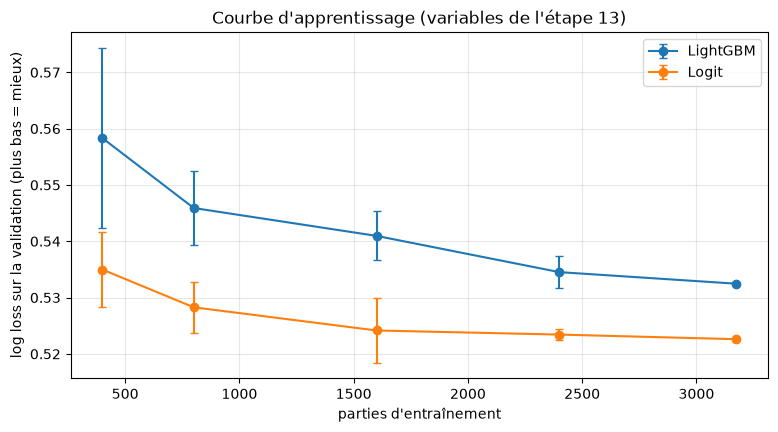

LightGBM : log loss 0.5345 à 2400 parties -> 0.5325 à 3175 (+0.0021 pour 775 parties de plus)
Logit : log loss 0.5234 à 2400 parties -> 0.5226 à 3175 (+0.0008 pour 775 parties de plus)


In [4]:
fig, ax = plt.subplots()
for name, g in lc.groupby("modèle"):
    s = g.groupby("parties")["log_loss"].agg(["mean", "std"]).fillna(0)
    ax.errorbar(s.index, s["mean"], yerr=s["std"], marker="o", capsize=3, label=name)
ax.set(xlabel="parties d'entraînement", ylabel="log loss sur la validation (plus bas = mieux)",
       title="Courbe d'apprentissage (variables de l'étape 13)")
ax.legend()
plt.show()

for name, g in lc.groupby("modèle"):
    m = g.groupby("parties")["log_loss"].mean()
    gain = m.iloc[-2] - m.iloc[-1]
    print(f"{name} : log loss {m.iloc[-2]:.4f} à {m.index[-2]} parties -> {m.iloc[-1]:.4f} à "
          f"{m.index[-1]} ({gain:+.4f} pour {m.index[-1] - m.index[-2]} parties de plus)")

## 3. Les nouvelles variables, une par une

Pour chaque groupe, on ajoute ses variables au modèle de référence (logistique, 11 variables),
et on compare en validation croisée, **pli par pli** comme à l'étape 13.

**Règle de décision, fixée avant de voir les résultats** : on garde un groupe s'il améliore
la log loss moyenne **et** gagne sur au moins **4 plis sur 5**. Sans règle fixée à l'avance,
on finirait par garder ce qui a eu de la chance (avec 5 groupes testés, l'un d'eux peut
sembler aider par hasard).

In [5]:
base_cv = cross_validate(make_logit, FEATURES, train)

def compare(cols):
    cv = cross_validate(make_logit, FEATURES + cols, train)
    d = cv["log_loss"] - base_cv["log_loss"]
    return cv, {"log loss": cv["log_loss"].mean(), "écart moyen": d.mean(),
                "plis gagnés": int((d < 0).sum()), "auc": cv["auc"].mean()}

rows = {"référence (11 variables)": {"log loss": base_cv["log_loss"].mean(), "écart moyen": 0.0,
                                     "plis gagnés": np.nan, "auc": base_cv["auc"].mean()}}
for group, cols in GROUPS.items():
    rows[group] = compare(cols)[1]
rows["tous les groupes"] = compare(NEW)[1]
groups_table = pd.DataFrame(rows).T
groups_table.round(4)

,log loss,écart moyen,plis gagnés,auc
référence (11 variables),0.5297,0.0000,NaN,0.8075
or à 10 min,0.5290,-0.0007,4.0,0.8083
niveaux,0.5303,0.0007,2.0,0.8068
joueur le plus riche,0.5277,-0.0020,4.0,0.8095
joueurs en vie à 15:00,0.5298,0.0001,1.0,0.8074
dragons par type,0.5358,0.0061,0.0,0.8038
tous les groupes,0.5339,0.0042,2.0,0.8053


In [6]:
KEPT = [g for g, cols in GROUPS.items()
        if groups_table.loc[g, "écart moyen"] < 0 and groups_table.loc[g, "plis gagnés"] >= 4]
KEPT_COLS = [c for g in KEPT for c in GROUPS[g]]
print("Groupes gardés :", KEPT or "aucun")

if KEPT:
    kept_cv, kept_row = compare(KEPT_COLS)
    print(f"Ensemble des groupes gardés : log loss {kept_row['log loss']:.4f} "
          f"({kept_row['écart moyen']:+.4f}, {kept_row['plis gagnés']}/5 plis gagnés)")
IMPROVED_COLS = FEATURES + KEPT_COLS

Groupes gardés : ['or à 10 min', 'joueur le plus riche']
Ensemble des groupes gardés : log loss 0.5273 (-0.0024, 4/5 plis gagnés)


## 4. Réglage de la régularisation

La logistique de scikit-learn est **pénalisée** (paramètre `C`, 1 par défaut) : plus `C` est petit,
plus les coefficients sont tirés vers 0, ce qui protège du surapprentissage quand les variables
sont nombreuses ou se recoupent. On teste quelques valeurs en validation croisée,
avec les variables retenues ci-dessus.

In [7]:
c_rows = []
for C in [0.001, 0.01, 0.1, 1.0, 10.0]:
    cv = cross_validate(lambda C=C: make_logit(C=C), IMPROVED_COLS, train)
    c_rows.append({"C": C, "log_loss": cv["log_loss"].mean(), "auc": cv["auc"].mean()})
c_table = pd.DataFrame(c_rows).set_index("C")
BEST_C = float(c_table["log_loss"].idxmin())
print(f"Meilleur C : {BEST_C}")
c_table.round(4)

Meilleur C : 0.1


,log_loss,auc
C,,
0.001,0.5491,0.8061
0.010,0.5263,0.8101
0.100,0.5258,0.8105
1.000,0.5273,0.8098
10.000,0.5276,0.8097


## 5. LightGBM avec toutes les variables

Les arbres choisissent eux-mêmes les variables utiles : on donne à LightGBM **toutes** les
variables (étape 13 + or par poste + toutes les nouvelles), avec le réglage de l'étape 13.
S'il ne gagne toujours pas, on saura que ce n'est pas faute d'informations.

In [8]:
LGBM_ALL = FEATURES + ROLE_FEATURES + NEW
lgbm_cv = {
    "LightGBM, variables de l'étape 13": cross_validate(lambda: make_lgbm(**BEST_LGBM),
                                                         FEATURES + ROLE_FEATURES, train),
    "LightGBM, toutes les variables": cross_validate(lambda: make_lgbm(**BEST_LGBM), LGBM_ALL, train),
}
pd.DataFrame({k: v[["log_loss", "auc"]].mean() for k, v in lgbm_cv.items()}).T.round(4)

,log_loss,auc
"LightGBM, variables de l'étape 13",0.5353,0.8048
"LightGBM, toutes les variables",0.5376,0.8028


## 6. Le test final (une seule fois)

Quatre modèles réentraînés sur tout l'entraînement, évalués sur les 953 parties du test :
- **Référence** : la logistique de l'étape 13 (doit redonner 0,524) ;
- **Logit amélioré** : variables retenues en partie 3 et `C` de la partie 4 ;
- **LightGBM, toutes les variables** ;
- **Moyenne** des probabilités du Logit amélioré et de LightGBM (un *ensemble* très simple :
  quand deux modèles se trompent un peu différemment, la moyenne se trompe souvent moins).

Chaque modèle est comparé à la référence par bootstrap apparié.

In [9]:
make_best_logit = lambda: make_logit(C=BEST_C)
test_pred = {
    "Référence (étape 13)": fit_predict(make_logit, FEATURES, train, test)[0],
    "Logit amélioré": fit_predict(make_best_logit, IMPROVED_COLS, train, test)[0],
    "LightGBM, toutes les variables": fit_predict(lambda: make_lgbm(**BEST_LGBM), LGBM_ALL, train, test)[0],
}
test_pred["Moyenne Logit amélioré + LightGBM"] = (test_pred["Logit amélioré"]
                                                 + test_pred["LightGBM, toutes les variables"]) / 2

y_test = test[TARGET].to_numpy()
ref = test_pred["Référence (étape 13)"]
final = []
for name, p in test_pred.items():
    row = {"modèle": name, **evaluate(y_test, p)}
    if name != "Référence (étape 13)":
        diff, low, high = paired_bootstrap(y_test, ref, p)
        row.update({"écart vs référence": diff, "IC 95 % bas": low, "IC 95 % haut": high})
    final.append(row)
pd.DataFrame(final).set_index("modèle").round(4)

,log_loss,brier,auc,accuracy,écart vs référence,IC 95 % bas,IC 95 % haut
modèle,,,,,,,
Référence (étape 13),0.5242,0.1752,0.8134,0.7408,NaN,NaN,NaN
Logit amélioré,0.5270,0.1763,0.8113,0.7377,0.0028,-0.0019,0.0074
"LightGBM, toutes les variables",0.5302,0.1776,0.8088,0.7314,0.0061,-0.0006,0.0128
Moyenne Logit amélioré + LightGBM,0.5275,0.1765,0.8111,0.7335,0.0033,-0.0017,0.0083


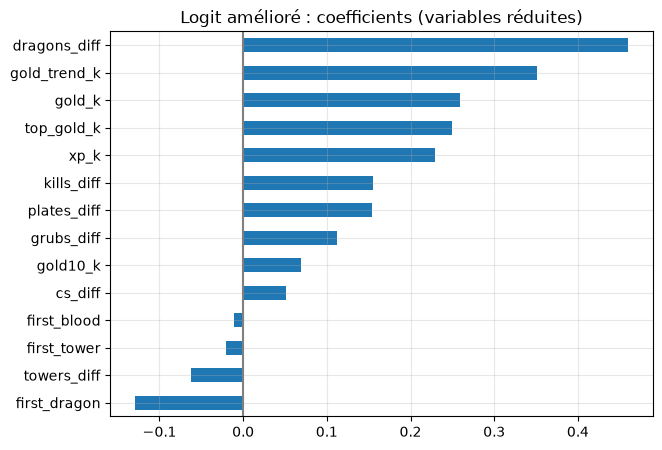

In [10]:
if KEPT_COLS:
    model = fit_predict(make_best_logit, IMPROVED_COLS, train, test)[1][-1]
    coefs = pd.Series(model.coef_[0], index=IMPROVED_COLS).sort_values()
    coefs.plot.barh(title="Logit amélioré : coefficients (variables réduites)", figsize=(7, 5))
    plt.axvline(0, color="grey")
    plt.show()
else:
    print("Aucun groupe gardé : le Logit amélioré n'a que les 11 variables de l'étape 13.")

## 7. Conclusions

Résultat principal : **aucune des pistes testées n'améliore la prédiction sur le test.** La régression logistique de l'étape 13 (11 variables, log loss 0,524) reste le meilleur modèle. C'est un résultat négatif, mais il est net, et il dit où se trouve la limite.

**1. Plus de parties n'aiderait presque pas la logistique.** Sur la courbe d'apprentissage, sa log loss passe de 0,5242 (1 600 parties) à 0,5226 (3 175 parties), dont seulement −0,0008 pour les 775 dernières parties : la courbe est presque plate. LightGBM descend encore (0,5410 → 0,5325, dont −0,0021 pour les 775 dernières), mais il part de beaucoup plus haut. Même en continuant à ce rythme (qui ralentit), 4 fois plus de parties ne suffiraient probablement pas à combler l'écart d'environ 0,01 avec la logistique. **Conclusion : la collecte de 20 000 parties ne vaut pas deux soirées pour ce modèle à 15 min.**

**2. Les nouvelles variables répètent surtout l'or.** Elles sont toutes corrélées à 0,80-0,89 avec l'écart d'or (sauf les joueurs en vie et les dragons par type, faibles).
- En validation croisée, deux groupes passent la règle fixée à l'avance (au moins 4 plis sur 5) : « joueur le plus riche » (−0,0020) et « or à 10 min » (−0,0007). Ensemble, et avec `C = 0,1`, la log loss de validation passe de 0,5297 à 0,5258.
- **Sur le test, ce gain disparaît** : Logit amélioré 0,5270 contre 0,5242 pour la référence (+0,003, IC 95 % −0,002 à +0,007, pas de différence nette). Les gains de validation étaient de l'ordre du bruit. C'est la « malédiction du gagnant » : en testant 5 groupes, on finit par en garder qui ont eu de la chance sur ces plis, même avec une règle stricte.
- Les dragons par type font **moins bien** (+0,006, 0 pli sur 5) : 6 colonnes rares ajoutées pour une information déjà résumée par `dragons_diff`. Les niveaux et les joueurs en vie ne changent rien.

**3. LightGBM ne profite pas des variables en plus** : 0,5376 en validation avec toutes les variables, contre 0,5353 sans. Sur le test, 0,530. La moyenne Logit + LightGBM (0,528) ne bat pas non plus la référence.

**4. Le réglage de la régularisation compte peu** : `C` entre 0,01 et 10 donne 0,526 à 0,528 ; seul `C = 0,001` (trop fort) dégrade nettement (0,549).

**Ce qu'on en retient.** À la minute 15, ces données (état de la partie résumé en écarts) donnent environ 0,52 de log loss et 74 % de bons pronostics, et ni plus de parties, ni plus de variables dérivées de l'or, ni un modèle plus souple ne déplacent ce plafond. Une information vraiment nouvelle devrait venir d'ailleurs (niveau des joueurs, informations sur les champions), et le gain le plus sûr viendra de prédire **plus tard dans la partie** : c'est le GRU minute par minute prévu en janvier.

**Décision.** Modèle conservé : la logistique de l'étape 13. `build_extra_features()` reste dans `features.py` (documenté, réutilisable pour le GRU), mais n'est pas utilisé par le modèle retenu.
